# The stable variants as charts of one object

The literature on the $\Omega d$ problem offers a list of replacements for the transfer matrix: the stiffness matrix (Rokhlin and Wang), its inverse the compliance matrix, the hybrid matrix (Tan), and the scattering matrix. Pérez-Álvarez, Pernas-Salomón and Velasco worked out the relations between them for the matrix Sturm-Liouville problem and concluded that the hybrid and scattering matrices are stable for thick and for thin layers, and the stiffness matrix for thick layers only. This notebook reproduces those conclusions for optical multilayers, adds where each variant loses digits at particular thicknesses, and proposes one picture that explains all of it: the four matrices are coordinate charts on the same space, and each fails where its chart does.

## What this notebook shows

- A layer is a linear relation between the fields on its two faces. The transfer, stiffness, hybrid and scattering matrices write that relation as a graph over four different choices of "independent" half of the variables. Their composition rules are the matrix product, a Schur complement, and, for both the hybrid and the scattering matrix, the Redheffer star product.
- For a lossless layer the relation is a Lagrangian subspace, and the space of all of them is compact. The transfer matrices are an open part of it that leaves out the opaque limit; the stiffness and hybrid matrices are affine charts that leave out a hypersurface each; the scattering matrix referred to propagating waves is a coordinate on the whole space. Checked here: the symmetries that say "Lagrangian" in each chart, and the limit of a thick barrier, where the scattering matrix converges and the transfer matrix does not exist.
- Where each chart is singular. The stiffness matrix: thin layers and layers a whole number of half-waves thick. The hybrid matrix: layers an odd number of quarter-waves thick. Near these the computed reflection loses digits as $\epsilon/\delta$ with $\delta$ the distance to the singular thickness, although the exact answer has nothing special there.
- One sweep of a common scale factor over fifteen decades of thickness, for a one-channel stack and for a two-channel anisotropic one, shows all the regimes at once.
- The scattering-matrix recursion in layer amplitudes has singular points of its own, the poles of single interfaces (a surface plasmon of a lossless metal), but there it fails only at the exact point and not in a neighborhood.

## Conventions

As in notebooks 01 and 02. In a layer, $u''+q^2u=0$, $v=u'/w$, $\eta=q/w$, phase thickness $\varphi=qd$.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/omega_d (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, warnings, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # multilayer.py sits next to this notebook
import multilayer as ml
import mpmath as mp

warnings.filterwarnings("ignore", category=RuntimeWarning)
EPS = np.finfo(float).eps
K0 = ml.K0
FLOOR = 1e-17
clip = lambda e: np.clip(np.where(np.isfinite(e), e, 1e30), FLOOR, 1e4)

## 1. One layer, four matrices

The four numbers $(u_L,v_L,u_R,v_R)$ on the two faces of a layer satisfy two linear equations. Each matrix solves them for a different pair.

| matrix | given | returns | one layer |
|---|---|---|---|
| transfer $T$ | $u_L,v_L$ | $u_R,v_R$ | $\begin{pmatrix}\cos\varphi&\eta^{-1}\sin\varphi\\-\eta\sin\varphi&\cos\varphi\end{pmatrix}$ |
| stiffness $E$ | $u_L,u_R$ | $v_L,v_R$ | $\dfrac{\eta}{\sin\varphi}\begin{pmatrix}-\cos\varphi&1\\-1&\cos\varphi\end{pmatrix}$ |
| hybrid $H$ | $v_L,u_R$ | $u_L,v_R$ | $\dfrac{1}{\cos\varphi}\begin{pmatrix}-\eta^{-1}\sin\varphi&1\\1&-\eta\sin\varphi\end{pmatrix}$ |
| scattering $S$ | $a^+_L,a^-_R$ | $a^-_L,a^+_R$ | $\begin{pmatrix}0&e^{i\varphi}\\e^{i\varphi}&0\end{pmatrix}$ in the layer's own waves |

The stiffness matrix is the Dirichlet-to-Neumann map of the layer, and its inverse, the compliance matrix, has the same denominator. In the names of Pérez-Álvarez and coworkers, $T$ is the "associated transfer matrix", and the matrix that carries wave amplitudes instead of fields is the "coefficient transfer matrix".

For an evanescent layer the entries of $E$, $H$ and $S$ can all be written with $e^{i\varphi}$ and $e^{2i\varphi}$ only, which decay, and they tend to finite limits as the layer gets thick: $E\to\operatorname{diag}(i\eta,-i\eta)$, which says that each face sees a half-space. `multilayer.py` computes them that way. The cell checks the three field matrices against each other through the conversions

$$E=\frac1B\begin{pmatrix}-A&1\\-1&D\end{pmatrix},\qquad H=\frac1A\begin{pmatrix}-B&1\\1&C\end{pmatrix}\qquad\text{for }T=\begin{pmatrix}A&B\\C&D\end{pmatrix},\ \det T=1,$$

which also show where the charts end: $E$ needs $B\ne0$ and $H$ needs $A\ne0$.

In [3]:
rng = np.random.default_rng(0)
worst_E, worst_H = 0.0, 0.0
for _ in range(200):
    q, eta, d = complex(rng.uniform(0.5, 8), rng.uniform(0, 3)), complex(rng.uniform(0.5, 3), rng.uniform(-1, 1)), rng.uniform(0.05, 1.0)
    A, B, C, D = ml.T_layer(q, eta, d)
    E, H = np.array(ml.E_layer(q, eta, d)), np.array(ml.H_layer(q, eta, d))
    worst_E = max(worst_E, np.abs(E - np.array([-A, 1, -1, D]) / B).max() / np.abs(E).max())
    worst_H = max(worst_H, np.abs(H - np.array([-B, 1, 1, C]) / A).max() / np.abs(H).max())
check("stiffness matrix from decaying exponentials against its expression in T, 200 random layers", worst_E, 1e-11)
check("hybrid matrix from decaying exponentials against its expression in T, 200 random layers", worst_H, 1e-11)

q, eta = 5.0j, 2.0j                                  # an evanescent layer, s polarization
E_thick, H_thick, H_thin = ml.E_layer(q, eta, 60.0), ml.H_layer(q, eta, 60.0), ml.H_layer(q, eta, 1e-14)
check("thick evanescent layer: E -> diag(i eta, -i eta)", max(abs(E_thick[0] - 1j * eta), abs(E_thick[3] + 1j * eta), abs(E_thick[1]), abs(E_thick[2])), 1e-14)
check("thick evanescent layer: H -> diag(-i/eta, -i eta)", max(abs(H_thick[0] + 1j / eta), abs(H_thick[3] + 1j * eta), abs(H_thick[1]), abs(H_thick[2])), 1e-14)
check("layer of vanishing thickness: H -> [[0, 1], [1, 0]]", max(abs(H_thin[0]), abs(H_thin[3]), abs(H_thin[1] - 1), abs(H_thin[2] - 1)), 1e-12)
print(f"the same thin layer in the stiffness matrix: |E11| = {abs(ml.E_layer(q, eta, 1e-14)[0]):.2e}")

PASS  stiffness matrix from decaying exponentials against its expression in T, 200 random layers: got 6.03716e-16, target 0, |diff| 6.04e-16 <= 1e-11
PASS  hybrid matrix from decaying exponentials against its expression in T, 200 random layers: got 8.04144e-16, target 0, |diff| 8.04e-16 <= 1e-11
PASS  thick evanescent layer: E -> diag(i eta, -i eta): got 2.05928e-130, target 0, |diff| 2.06e-130 <= 1e-14
PASS  thick evanescent layer: H -> diag(-i/eta, -i eta): got 1.02964e-130, target 0, |diff| 1.03e-130 <= 1e-14
PASS  layer of vanishing thickness: H -> [[0, 1], [1, 0]]: got 1.00031e-13, target 0, |diff| 1.00e-13 <= 1e-12
the same thin layer in the stiffness matrix: |E11| = 4.00e+13


## 2. What the four matrices are charts of

Take a lossless stack at real $\beta$. In the variables $(u,v)$ the equations are real, and the transfer matrix preserves the Wronskian $\omega(\psi_1,\psi_2)=u_1v_2-u_2v_1$, which for a complex field is its power flux, $\operatorname{Im}(u^*v)$. So $T$ is in $\mathrm{SL}(2,\mathbb R)=\mathrm{Sp}(2,\mathbb R)$, and with $n$ channels in $\mathrm{Sp}(2n,\mathbb R)$.

Now look at the stack as a relation: the set $\Gamma$ of pairs $(\psi_L,\psi_R)$ that it allows. $\Gamma$ is a subspace of dimension $2n$ in a space of dimension $4n$, and flux conservation says that the form $\omega_L-\omega_R$ vanishes on it: $\Gamma$ is a Lagrangian subspace. Composition of stacks is composition of relations. The space of all Lagrangian subspaces, the Lagrangian Grassmannian $\Lambda(2n)$, is compact, of dimension $n(2n+1)$, the same as the dimension of $\mathrm{Sp}(2n,\mathbb R)$, and by a theorem of Arnold it is $\mathrm U(2n)/\mathrm O(2n)$, which can be realized as the set of symmetric unitary $2n\times2n$ matrices.

In this picture:

- **Transfer matrix.** $\Gamma$ written as a graph over $\psi_L$. Every $T$ gives a $\Gamma$, but not the reverse: the graphs are an open dense part of $\Lambda(2n)$, and a sequence of $T$ can run off to infinity while $\Gamma$ converges. That is what a thick barrier does. Its limit is the relation "$\psi_L$ on the line of the wave that decays into the barrier, and $\psi_R$ likewise, with no connection between them", which is a perfectly good Lagrangian subspace and not the graph of any matrix.
- **Stiffness matrix.** $\Gamma$ as a graph over $(u_L,u_R)$: in the language of mechanics with $z$ as time, a generating function of the first kind, a function of the old and new coordinates. It does not exist when there is a nonzero solution with $u_L=u_R=0$, and the identity (a layer of zero thickness) is the standard example of a map without one.
- **Hybrid matrix.** $\Gamma$ as a graph over $(v_L,u_R)$, a generating function of the second kind, which does generate the identity. It does not exist when there is a solution with $v_L=u_R=0$.
- **Scattering matrix.** $\Gamma$ as a graph over the incoming waves of two propagating reference media. Flux conservation makes $S$ unitary and reciprocity makes it symmetric, so it is a point of $\mathrm U(2n)/\mathrm O(2n)$ directly: a coordinate on all of $\Lambda(2n)$, with no part left out. With absorption $\Gamma$ is no longer Lagrangian but dissipative, and $S$ is a contraction.

Lagrangian means symmetric in each chart: $E$ with the sign of its second row changed is a symmetric matrix, $H$ is symmetric, $S$ in power-normalized amplitudes is symmetric. For a stack these are the reciprocity relations. The cell checks them on random lossless stacks, and then follows a barrier to its opaque limit.

In [4]:
worst = dict(T_real=0.0, det=0.0, E_sym=0.0, H_sym=0.0, S_sym=0.0, S_unit=0.0)
for trial in range(40):
    layers = [(rng.choice([1.0, 2.1, 6.0, 12.0, -3.0]), rng.uniform(0.05, 0.4)) for _ in range(rng.integers(2, 7))]
    st = ml.Stack(12.0, layers, 6.0)                 # outer media propagating at every beta used
    beta, pol = rng.uniform(0.2, 2.2), rng.choice(["s", "p"])
    ea, ls, eb = st.params(beta, pol)
    M = np.array(ml.T_forward(ls))
    E = np.array(ml.chain([ml.E_layer(*L) for L in ls], ml.E_compose))
    H = np.array(ml.chain([ml.H_layer(*L) for L in ls], ml.star))
    r, tp, t, rp = ml.S_stack(ls, ea, eb)
    Sn = np.array([[r, tp * np.sqrt(ea / eb)], [t * np.sqrt(eb / ea), rp]])       # power-normalized
    sc = np.abs(M).max()
    worst["T_real"] = max(worst["T_real"], np.abs(M.imag).max() / sc)
    worst["det"] = max(worst["det"], abs(M[0] * M[3] - M[1] * M[2] - 1) / sc ** 2)
    worst["E_sym"] = max(worst["E_sym"], abs(E[1] + E[2]) / np.abs(E).max(), np.abs(E.imag).max() / np.abs(E).max())
    worst["H_sym"] = max(worst["H_sym"], abs(H[1] - H[2]) / np.abs(H).max())
    worst["S_sym"] = max(worst["S_sym"], abs(Sn[0, 1] - Sn[1, 0]))
    worst["S_unit"] = max(worst["S_unit"], np.abs(Sn.conj().T @ Sn - np.eye(2)).max())
print("40 random lossless stacks (layers with negative permittivity included), both polarizations:")
check("T is real in the variables (u, v)", worst["T_real"], 1e-12)
check("det T = 1, relative to the square of the largest entry", worst["det"], 1e-12)
check("stiffness: real, and E12 = -E21", worst["E_sym"], 1e-9)
check("hybrid: H12 = H21", worst["H_sym"], 1e-9)
check("scattering, power-normalized: symmetric", worst["S_sym"], 1e-12)
check("scattering, power-normalized: unitary", worst["S_unit"], 1e-12)

print()
print("a barrier of growing thickness between two propagating media: the relation converges, the transfer matrix leaves")
print("  kappa d    largest |T entry|    |S12| (normalized)    distance of S from its limit    exp(-kappa d)")
eta_o, q_b = 3.0, 4.0j
S_inf = np.array(ml.S_stack([(q_b, q_b, 400.0)], eta_o, eta_o))
dist = []
for kd in (2.0, 8.0, 18.0, 36.0, 100.0, 700.0, 720.0):
    L = [(q_b, q_b, kd / abs(q_b))]
    S = np.array(ml.S_stack(L, eta_o, eta_o))
    Tm = np.abs(np.array(ml.T_forward(L))).max()
    dist.append(np.abs(S - S_inf).max())
    print(f"  {kd:7.1f}    {Tm:17.3e}    {abs(S[1]):18.3e}    {dist[-1]:28.3e}    {np.exp(-kd):13.3e}")
check("the limit is two separate total reflections: |r| = |r'| = 1 and t = 0", max(abs(abs(S_inf[0]) - 1), abs(abs(S_inf[3]) - 1), abs(S_inf[1])), 1e-15)
check("distance of S from its limit at kappa d = 8, in units of exp(-8) (an order-one prefactor)", dist[1] / np.exp(-8.0), 2.0, 2.0)
assert not np.isfinite(np.abs(np.array(ml.T_forward([(q_b, q_b, 720.0 / abs(q_b))]))).max())

40 random lossless stacks (layers with negative permittivity included), both polarizations:
PASS  T is real in the variables (u, v): got 0, target 0, |diff| 0.00e+00 <= 1e-12
PASS  det T = 1, relative to the square of the largest entry: got 4.1413e-16, target 0, |diff| 4.14e-16 <= 1e-12
PASS  stiffness: real, and E12 = -E21: got 5.40568e-15, target 0, |diff| 5.41e-15 <= 1e-09
PASS  hybrid: H12 = H21: got 2.85412e-32, target 0, |diff| 2.85e-32 <= 1e-09
PASS  scattering, power-normalized: symmetric: got 4.44089e-16, target 0, |diff| 4.44e-16 <= 1e-12
PASS  scattering, power-normalized: unitary: got 3.55273e-15, target 0, |diff| 3.55e-15 <= 1e-12

a barrier of growing thickness between two propagating media: the relation converges, the transfer matrix leaves
  kappa d    largest |T entry|    |S12| (normalized)    distance of S from its limit    exp(-kappa d)
      2.0            1.451e+01             2.559e-01                       2.559e-01        1.353e-01
      8.0            5.962e+03

## 3. Composition

Joining stack $A$ to stack $B$ identifies the fields on the right face of $A$ with those on the left face of $B$ and eliminates them. What this does to the matrices depends on which of the eliminated variables each matrix treats as given.

- Transfer matrices: the output of $A$ is the input of $B$, so $T=T_BT_A$.
- Stiffness matrices: the midpoint $u_m$ is given to both, and the two expressions for $v_m$ are equated. That is the Schur complement of the midpoint block of the assembled matrix, $u_m=(B_{11}-A_{22})^{-1}(A_{21}u_L-B_{12}u_R)$: the elimination of an interior node, as in the assembly of finite elements.
- Hybrid and scattering matrices: what $A$ returns on the right is what $B$ is given on the left, and the reverse. The two-ports are wired back to back, and the loop is closed by $(1-B_{11}A_{22})^{-1}$. This is the Redheffer star product, for both. The hybrid recursion of Tan and the scattering recursion of Ko and Inkson and of Li are the same algebra on different variables.

The rules are associative, as composition of relations must be, and the cell checks that on a random stack by composing left to right, right to left, and in two halves.

In [5]:
layers = [(rng.uniform(1, 12) * (1 + 0.02j), rng.uniform(0.05, 0.3)) for _ in range(8)]
st = ml.Stack(2.25, layers, 1.0)
ea, ls, eb = st.params(0.6, "p")
ref = ml.ref_rt(st, 0.6, "p")


def orders(mats, compose):
    left = ml.chain(mats, compose)
    right = mats[-1]
    for X in mats[-2::-1]:
        right = compose(X, right)
    halves = compose(ml.chain(mats[:4], compose), ml.chain(mats[4:], compose))
    return left, right, halves


worst = 0.0
for name, mats, compose, finish in (("stiffness", [ml.E_layer(*L) for L in ls], ml.E_compose, ml.rt_from_E),
                                    ("hybrid", [ml.H_layer(*L) for L in ls], ml.star, ml.rt_from_H)):
    for X in orders(mats, compose):
        r, t = finish(X, ea, eb)
        worst = max(worst, ml.relerr(r, ref[0]), ml.relerr(t, ref[1]))
check("stiffness and hybrid matrices of 8 layers, composed in three orders: r and t against the reference", worst, 1e-12)

PASS  stiffness and hybrid matrices of 8 layers, composed in three orders: r and t against the reference: got 1.07394e-14, target 0, |diff| 1.07e-14 <= 1e-12


## 4. Where each chart is singular

A lossless film of index 1.5 between two thin high-index layers, at normal incidence, with its phase thickness $\varphi$ scanned through two and a half half-waves. The exact reflection coefficient is a smooth function of $\varphi$ with nothing remarkable at multiples of $\pi/2$. The stiffness matrix of the film does not exist at $\varphi=m\pi$, where the film has a solution vanishing on both faces, and the hybrid matrix does not exist at $\varphi=(m+\tfrac12)\pi$.

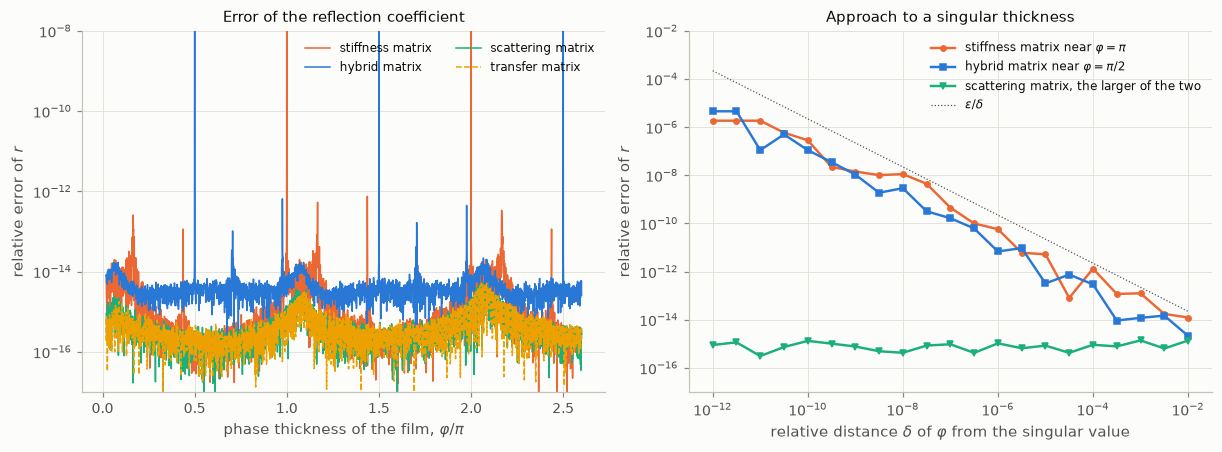

|r| over the scan: 0.138 to 0.805
PASS  stiffness matrix: largest error away from whole half-waves (more than 0.02 pi): got 7.5254e-13, target 0, |diff| 7.53e-13 <= 5e-12
PASS  hybrid matrix: largest error away from odd quarter-waves (more than 0.02 pi): got 6.51258e-13, target 0, |diff| 6.51e-13 <= 5e-12
largest error within 0.02 pi of the singular thicknesses: stiffness 1.5e-01, hybrid 2.1e-01
PASS  scattering matrix: largest error over the scan: got 5.25418e-15, target 0, |diff| 5.25e-15 <= 2e-14
PASS  transfer matrix: largest error over the scan: got 5.00901e-15, target 0, |diff| 5.01e-15 <= 2e-14
PASS  slope of the stiffness-matrix error against the distance from phi = pi: got -0.901874, target -1, |diff| 9.81e-02 <= 1e-01
PASS  slope of the hybrid-matrix error against the distance from phi = pi/2: got -0.954422, target -1, |diff| 4.56e-02 <= 1e-01
at the double nearest to the singular thickness: stiffness 1.5e-01, hybrid 2.1e-01
stiffness: the composition denominator of the first

In [6]:
n_f = 1.5
cavity = lambda phi: ml.Stack(2.25, [(6.0, 0.11), (n_f ** 2, phi / (K0 * n_f)), (6.0, 0.07)], 1.0)


def chart_errors(phi):
    st = cavity(phi)
    ea, ls, eb = st.params(0.0, "s")
    ref = ml.ref_rt(st, 0.0, "s")
    return [ml.relerr(ml.rt_from_backward(ml.T_backward(ls), ea, eb)[0], ref[0]), ml.relerr(ml.rt_E(ls, ea, eb)[0], ref[0]),
            ml.relerr(ml.rt_H(ls, ea, eb)[0], ref[0]), ml.relerr(ml.S_stack(ls, ea, eb)[0], ref[0]), float(abs(ref[0]))]


phis = np.linspace(0.02, 2.6, 2581) * np.pi
C = np.array([chart_errors(p) for p in phis])

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))
ax = axes[0]
ax.semilogy(phis / np.pi, clip(C[:, 1]), color=CAT[1], lw=1.0, label="stiffness matrix")
ax.semilogy(phis / np.pi, clip(C[:, 2]), color=CAT[0], lw=1.0, label="hybrid matrix")
ax.semilogy(phis / np.pi, clip(C[:, 3]), color=CAT[2], lw=1.0, label="scattering matrix")
ax.semilogy(phis / np.pi, clip(C[:, 0]), color=CAT[3], lw=1.0, ls="--", label="transfer matrix")
ax.set(xlabel=r"phase thickness of the film, $\varphi/\pi$", ylabel="relative error of $r$", ylim=(1e-17, 1e-8),
       title="Error of the reflection coefficient")
ax.legend(loc="upper right", fontsize=8, ncol=2)

# approach to one singular point of each chart
deltas = 10.0 ** np.arange(-12, -1.9, 0.5)
appr_E = np.array([chart_errors(np.pi * (1 + dl))[1] for dl in deltas])
appr_H = np.array([chart_errors(np.pi / 2 * (1 + dl))[2] for dl in deltas])
appr_S = np.array([max(chart_errors(np.pi * (1 + dl))[3], chart_errors(np.pi / 2 * (1 + dl))[3]) for dl in deltas])
ax = axes[1]
ax.loglog(deltas, clip(appr_E), "o-", ms=3.5, color=CAT[1], label=r"stiffness matrix near $\varphi=\pi$")
ax.loglog(deltas, clip(appr_H), "s-", ms=3.5, color=CAT[0], label=r"hybrid matrix near $\varphi=\pi/2$")
ax.loglog(deltas, clip(appr_S), "v-", ms=3.5, color=CAT[2], label="scattering matrix, the larger of the two")
ax.loglog(deltas, EPS / deltas, color=INK2, lw=0.8, ls=":", label=r"$\epsilon/\delta$")
ax.set(xlabel=r"relative distance $\delta$ of $\varphi$ from the singular value", ylabel="relative error of $r$", ylim=(1e-17, 1e-2),
       title="Approach to a singular thickness")
ax.legend(loc="upper right", fontsize=8)
plt.show()

frac = (phis / np.pi) % 1.0
near_int = np.minimum(frac, 1 - frac) < 0.02
near_half = np.abs(frac - 0.5) < 0.02
print(f"|r| over the scan: {C[:, 4].min():.3f} to {C[:, 4].max():.3f}")
check("stiffness matrix: largest error away from whole half-waves (more than 0.02 pi)", C[~near_int, 1].max(), 5e-12)
check("hybrid matrix: largest error away from odd quarter-waves (more than 0.02 pi)", C[~near_half, 2].max(), 5e-12)
print(f"largest error within 0.02 pi of the singular thicknesses: stiffness {C[near_int, 1].max():.1e}, hybrid {C[near_half, 2].max():.1e}")
assert C[near_int, 1].max() > 1e-11 and C[near_half, 2].max() > 1e-11
check("scattering matrix: largest error over the scan", C[:, 3].max(), 2e-14)
check("transfer matrix: largest error over the scan", C[:, 0].max(), 2e-14)
sl_E = np.polyfit(np.log(deltas), np.log(appr_E), 1)[0]
sl_H = np.polyfit(np.log(deltas), np.log(appr_H), 1)[0]
check("slope of the stiffness-matrix error against the distance from phi = pi", sl_E, 0.15, -1.0)
check("slope of the hybrid-matrix error against the distance from phi = pi/2", sl_H, 0.15, -1.0)
at_E, at_H = chart_errors(np.pi)[1], chart_errors(np.pi / 2)[2]
print(f"at the double nearest to the singular thickness: stiffness {at_E:.1e}, hybrid {at_H:.1e}")

# the smaller spikes: singular thicknesses of the partial stack (first layer plus film) met during composition
piv_E, piv_H = [], []
for p_ in phis:
    ea, ls, eb = cavity(p_).params(0.0, "s")
    a, b = ml.E_layer(*ls[0]), ml.E_layer(*ls[1])
    piv_E.append((b[0] - a[3]).real)                 # the denominator of the stiffness composition
    a, b = ml.H_layer(*ls[0]), ml.H_layer(*ls[1])
    piv_H.append((1 - b[0] * a[3]).real)             # the denominator of the star product
piv_E, piv_H = np.array(piv_E), np.array(piv_H)
for name, piv, col, own in (("stiffness", piv_E, 1, near_int), ("hybrid", piv_H, 2, near_half)):
    zeros = [i for i in range(len(phis) - 1) if piv[i] * piv[i + 1] < 0 and abs(piv[i]) < 1e3 and not own[i]]
    local = [C[max(i - 3, 0):i + 4, col].max() for i in zeros]
    print(f"{name}: the composition denominator of the first two layers changes sign at phi/pi = {np.round(phis[zeros] / np.pi, 3)}; "
          f"largest error within 3 grid points of each: {', '.join(f'{x:.0e}' for x in local)}")
    assert len(zeros) >= 2 and min(local) > 20 * np.median(C[:, col])

The tall spikes of the left panel sit at the half-waves for the stiffness matrix and at the quarter-waves for the hybrid matrix, and the right panel gives their shape: the error is $\epsilon/\delta$. A singular thickness is a pole of the layer's matrix; the reflection coefficient is assembled from entries of size $1/\delta$ that cancel, and loses that many digits. The smaller spikes between them are the same thing one level up. During composition the film is joined to the layer before it, and the result to the layer after it, and each partial stack has singular thicknesses of its own, where the denominator of the composition rule vanishes; the last lines of the output locate those of the first step.

These are singularities of the description. They move if the stack is cut into layers differently, they have nothing to do with the resonances of the structure, and for an absorbing or evanescent layer they are off the real axis and the charts are fine. They matter for the lossless, propagating layers of interference coatings, where half-wave and quarter-wave thicknesses are the design values.

## 5. Thin and thick: fifteen decades of thickness

The test of Pérez-Álvarez and coworkers' conclusions is a stack whose thicknesses are all multiplied by a common factor, from $10^{-12}$ to $10^{3}$.

- One channel: glass, then SiO$_2$, silver, a high-index layer and an air gap, on air, in p polarization at $\beta=1.2$, where the air layers are evanescent.
- Two channels: the uniaxial slab of notebook 02 twice, with an isotropic film between, between prisms of index 1.8 and 1.6, at $\beta=1.55$. The stiffness and hybrid matrices are those of the field halves $(E_x,E_y)$ and $(H_x,H_y)$.

two-channel sweep: 0.9 s


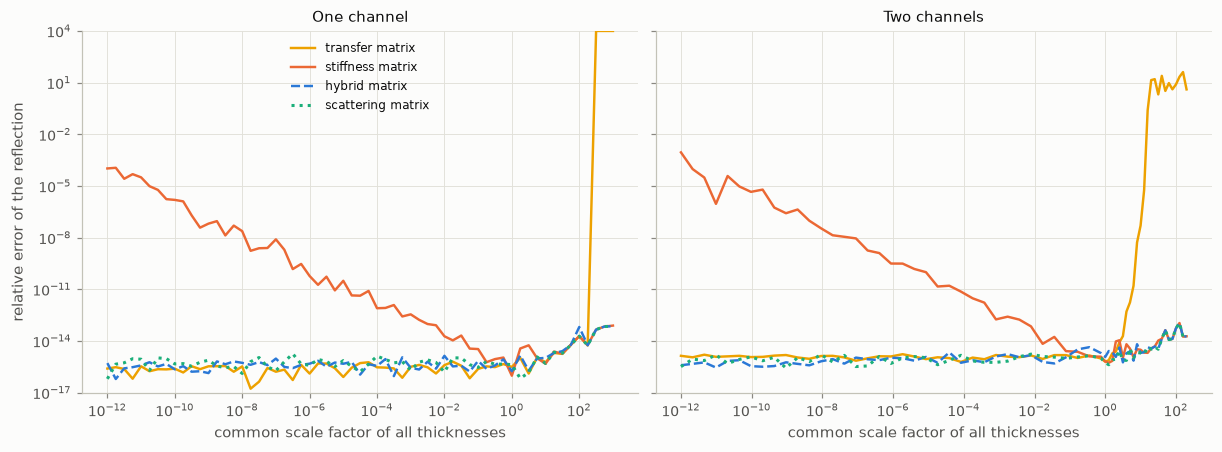

PASS  one channel: slope of the stiffness-matrix error against the scale, thin layers: got -1.0183, target -1, |diff| 1.83e-02 <= 2e-01
PASS  one channel: largest error of the hybrid matrix, all scales: got 7.1495e-14, target 0, |diff| 7.15e-14 <= 1e-12
PASS  one channel: largest error of the scattering matrix, all scales: got 7.11777e-14, target 0, |diff| 7.12e-14 <= 1e-12
PASS  one channel: largest error of the transfer matrix where it is finite: got 1.90441e-14, target 0, |diff| 1.90e-14 <= 1e-12
  the transfer matrix overflows from a scale of 316 on, where the sum of kappa d is 837
PASS  two channels: slope of the stiffness-matrix error against the scale, thin layers: got -0.945623, target -1, |diff| 5.44e-02 <= 2e-01
PASS  two channels: largest error of the hybrid matrix, all scales: got 1.09568e-13, target 0, |diff| 1.10e-13 <= 1e-12
PASS  two channels: largest error of the scattering matrix, all scales: got 1.10043e-13, target 0, |diff| 1.10e-13 <= 1e-12
  the transfer matrix ha

In [7]:
ag = -18.3 + 0.5j
base = [(2.1, 0.2), (ag, 0.05), (6.0, 0.15), (1.0, 0.3)]
scales1 = 10.0 ** np.arange(-12, 3.01, 0.25)
R1 = []
for sc in scales1:
    st = ml.Stack(2.25, [(e, d * sc) for e, d in base], 1.0)
    ea, ls, eb = st.params(1.2, "p")
    ref = ml.ref_rt(st, 1.2, "p")
    R1.append([ml.relerr(ml.rt_from_backward(ml.T_backward(ls), ea, eb)[0], ref[0]), ml.relerr(ml.rt_E(ls, ea, eb)[0], ref[0]),
               ml.relerr(ml.rt_H(ls, ea, eb)[0], ref[0]), ml.relerr(ml.S_stack(ls, ea, eb)[0], ref[0]),
               sum(abs(q.imag) * d for q, _, d in ls)])
R1 = np.array(R1)

n_o, n_e, beta2 = 1.5, 1.7, 1.55
eps_u = ml.uniaxial(n_o ** 2, n_e ** 2, np.pi / 2, np.radians(45))
Mu, Gu = ml.modes_aniso(eps_u, beta2), ml.berreman_G(eps_u, beta2)
Mf, Gf = ml.modes_aniso(4.0 * np.eye(3), beta2), ml.berreman_G(4.0 * np.eye(3), beta2)
Ma2, Mb2 = ml.modes_iso4(1.8 ** 2, beta2), ml.modes_iso4(1.6 ** 2, beta2)
kap_u = Mu.qp.imag.max()
base2 = (0.5, 0.2, 0.4)
scales2 = np.concatenate([10.0 ** np.arange(-12, -0.01, 0.33), 10.0 ** np.arange(0, 2.31, 0.1)])
R2 = []
t0 = time.time()
for sc in scales2:
    d1, d2, d3 = (b * sc for b in base2)
    L = [(Mu, d1), (Mf, d2), (Mu, d3)]
    Rr, Tr = ml.ref_block_rt(Ma2, [(Gu, d1), (Gf, d2), (Gu, d3)], Mb2, int(60 + 2 * kap_u * (d1 + d3) / np.log(10)))
    S = ml.block_S(Ma2, L, Mb2)
    R2.append([ml.mp_err(ml.block_T(Ma2, L, Mb2)[0], Rr), ml.mp_err(ml.block_E(Ma2, L, Mb2)[0], Rr), ml.mp_err(ml.block_H(Ma2, L, Mb2)[0], Rr),
               ml.mp_err(S[0], Rr), kap_u * (d1 + d3)])
R2 = np.array(R2)
print(f"two-channel sweep: {time.time() - t0:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0), sharey=True)
for ax, sc, R, title in ((axes[0], scales1, R1, "One channel"), (axes[1], scales2, R2, "Two channels")):
    ax.loglog(sc, clip(R[:, 0]), color=CAT[3], label="transfer matrix")
    ax.loglog(sc, clip(R[:, 1]), color=CAT[1], label="stiffness matrix")
    ax.loglog(sc, clip(R[:, 2]), color=CAT[0], ls="--", label="hybrid matrix")
    ax.loglog(sc, clip(R[:, 3]), color=CAT[2], ls=":", lw=2.0, label="scattering matrix")
    ax.set(xlabel="common scale factor of all thicknesses", ylim=(1e-17, 1e4), title=title)
axes[0].set_ylabel("relative error of the reflection")
axes[0].legend(loc="upper center", fontsize=8)
plt.show()

thin = scales1 <= 1e-6
sl = np.polyfit(np.log(scales1[thin]), np.log(R1[thin, 1]), 1)[0]
check("one channel: slope of the stiffness-matrix error against the scale, thin layers", sl, 0.25, -1.0)
check("one channel: largest error of the hybrid matrix, all scales", R1[:, 2].max(), 1e-12)
check("one channel: largest error of the scattering matrix, all scales", R1[:, 3].max(), 1e-12)
fin1 = np.isfinite(R1[:, 0])
check("one channel: largest error of the transfer matrix where it is finite", R1[fin1, 0].max(), 1e-12)
print(f"  the transfer matrix overflows from a scale of {scales1[~fin1].min():.0f} on, where the sum of kappa d is {R1[~fin1, 4].min():.0f}")
thin2 = scales2 <= 1e-6
check("two channels: slope of the stiffness-matrix error against the scale, thin layers", np.polyfit(np.log(scales2[thin2]), np.log(R2[thin2, 1]), 1)[0], 0.25, -1.0)
check("two channels: largest error of the hybrid matrix, all scales", R2[:, 2].max(), 1e-12)
check("two channels: largest error of the scattering matrix, all scales", R2[:, 3].max(), 1e-12)
i_bad = np.argmax(R2[:, 0] > 0.1)
print(f"  the transfer matrix has an error above 0.1 from a scale of {scales2[i_bad]:.1f} on, where kappa d of the two slabs together is {R2[i_bad, 4]:.0f}")
assert 25 < R2[i_bad, 4] < 60 and R2[scales2 <= 1.0, 0].max() < 1e-12

The two panels are the summary of the literature in one picture. The stiffness matrix fails toward thin layers as $\epsilon$ over the phase thickness and is exact for thick ones. The hybrid and scattering matrices are at rounding level across all fifteen decades, with one and with two channels. The transfer matrix is exact for thin layers; with one channel it stays exact until it overflows, and with two channels it is lost at $\kappa d\approx36$.

## 6. The scattering matrix in layer amplitudes: isolated poles

The scattering matrix that is a global coordinate is the one referred to propagating waves outside the stack. The recursion that computes it works with the amplitudes of each layer's own waves, and in an evanescent layer these are not normalized by flux. The reflection coefficient of a single interface between two evanescent waves, $(\eta_1-\eta_2)/(\eta_1+\eta_2)$, is not bounded by one, and it has a pole where $\eta_1+\eta_2=0$: the surface plasmon of the interface between a dielectric and a lossless metal, at $\beta_{sp}=\sqrt{\varepsilon_m\varepsilon_d/(\varepsilon_m+\varepsilon_d)}$ in p polarization.

The test is a prism, a dielectric gap, and a lossless metal half-space, with $\beta$ at and near $\beta_{sp}$ of the gap-metal interface. The reflection of the whole structure is a pure phase, smooth through that point.

In [8]:
eps_m, eps_d = -4.0, 2.25
beta_sp = np.sqrt(eps_m * eps_d / (eps_m + eps_d))
st_sp = ml.Stack(6.25, [(eps_d, 0.3)], eps_m)
print(f"beta_sp = {beta_sp:.6f}")
print("   delta     eta_1 + eta_2    scattering   two-wave vector   hybrid     stiffness   transfer")
rows = []
for delta in (0.0, 1e-15, 1e-12, 1e-9, 1e-6, 1e-3):
    b = beta_sp * (1 + delta)
    ea, ls, eb = st_sp.params(b, "p")
    ref = ml.ref_rt(st_sp, b, "p")
    e = [ml.relerr(ml.S_stack(ls, ea, eb)[0], ref[0]), ml.relerr(ml.rt_vector(ls, ea, eb, modal=True)[0], ref[0]), ml.relerr(ml.rt_H(ls, ea, eb)[0], ref[0]),
         ml.relerr(ml.rt_E(ls, ea, eb)[0], ref[0]), ml.relerr(ml.rt_from_backward(ml.T_backward(ls), ea, eb)[0], ref[0])]
    rows.append(e)
    print(f"  {delta:7.0e} {abs(ls[-1][1] + eb):15.1e} " + " ".join(f"{x:11.1e}" for x in e))
rows = np.array(rows)
assert not np.isfinite(rows[0, 0]), "at the exact pole the interface matrix is infinite"
check("scattering matrix: largest error at the five nonzero distances from the pole", rows[1:, 0].max(), 1e-11)
check("the other four: largest error over all rows, the pole included", rows[:, 1:].max(), 1e-11)

beta_sp = 2.267787
   delta     eta_1 + eta_2    scattering   two-wave vector   hybrid     stiffness   transfer
    0e+00         0.0e+00         inf     6.1e-15     3.2e-15     9.3e-14     1.0e-14
    1e-15         6.2e-15     3.7e-14     5.9e-14     3.7e-14     1.1e-13     3.9e-14
    1e-12         5.8e-12     2.3e-14     9.0e-15     3.0e-14     3.5e-14     2.8e-14
    1e-09         5.8e-09     1.1e-14     9.4e-15     1.4e-14     4.2e-14     4.7e-16
    1e-06         5.8e-06     2.1e-14     3.4e-14     2.8e-14     1.2e-15     3.7e-14
    1e-03         5.8e-03     1.8e-13     1.8e-13     1.0e-13     1.6e-13     1.7e-13
PASS  scattering matrix: largest error at the five nonzero distances from the pole: got 1.79401e-13, target 0, |diff| 1.79e-13 <= 1e-11
PASS  the other four: largest error over all rows, the pole included: got 1.75361e-13, target 0, |diff| 1.75e-13 <= 1e-11


At the double where $\eta_1+\eta_2$ is exactly zero the recursion divides by zero. One rounding unit away it is as accurate as the others, because the star product takes an infinite reflection coefficient to a finite limit the way a Möbius map takes the point at infinity. This is unlike the poles of the stiffness and hybrid matrices in section 4, which cost digits throughout a neighborhood. The recursion on a vector, which uses homogeneous coordinates, has no such point at all.

## Summary

| | thin layers | thick evanescent layers | particular thicknesses | composition |
|---|---|---|---|---|
| transfer matrix | exact | one channel: exact until overflow; more: lost at $\Delta\kappa\,d\approx36$ | none | product |
| stiffness (and compliance) | error $\epsilon/\varphi$ | exact | half-waves, error $\epsilon/\delta$ | Schur complement |
| hybrid | exact | exact | odd quarter-waves, error $\epsilon/\delta$ | star product |
| scattering | exact | exact | interface poles, the exact point only | star product |

The agreement with Pérez-Álvarez, Pernas-Salomón and Velasco is complete where they made a statement: hybrid and scattering matrices for all thicknesses, stiffness for thick layers only. The singular thicknesses of the stiffness and hybrid matrices are an addition. The geometric reading is that $T$, $E$ and $H$ are charts on the space of Lagrangian relations, each undefined on a set that is the boundary at infinity for $T$ and a hypersurface for $E$ and $H$, while the flux-normalized scattering matrix covers the space; and that descriptions in homogeneous coordinates (a rescaled vector, an orthonormal frame, Plücker coordinates) have no singular set.

## Caveats and open ends

- The identification of stacks with points of the Lagrangian Grassmannian is used here as an organizing picture. The standard facts in it are the theorem of Arnold and the Lagrangian property of the graph of a symplectic map; that the stiffness and hybrid matrices are the corresponding affine charts and the thick barrier a boundary point is elementary but was verified only through the numerical checks of section 2, not written out as a proof, and I did not find it stated in this form in the references I checked.
- The singular thicknesses were demonstrated for one lossless film at normal incidence and one interface pole. With several channels the singular sets are the zeros of determinants of blocks; they were not mapped.
- The scattering matrix was always computed in layer amplitudes. The variant referred to a fixed propagating reference medium between layers, which would make every partial matrix a contraction, was not implemented, so the statement that its conditioning is that of the physical resonances is an expectation.
- The compliance matrix was not computed separately.
- No operation counts or timings.